# Access to Public Health Facilities Across Districts in Sierra Leone
### COMM104 Data Science Fundamentals – Assignment 1: Identifying and Preparing Data for a Sierra Leone Development Problem

| | |
|---|---|
| **Student name** | _[]_ |
| **Student ID** | _[]_ |
| **Programme / Class** | _[DIT]_ |
| **Lecturer** | Mr. Augustine Foday Ngobie |

This notebook holds the technical work for the assignment: loading the dataset, exploring its structure and quality, cleaning and transforming it, and exporting analysis-ready files. The accompanying report explains the problem, the SDG link and the ethical considerations in full.

**Contents**
1. Setup
2. Problem, SDG and research questions (summary)
3. Data acquisition
4. Data understanding and exploration
5. Data cleaning and preparation
6. First look at the research questions
7. Data ethics notes
8. Cleaning log and references

## 1. Setup
Only open-source Python libraries are used: `pandas`, `numpy`, `matplotlib` and `shapely`. Install them with `pip install pandas numpy matplotlib shapely` if needed.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import shape, Point

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 110

RAW_FACILITIES = "who_health_facilities_sierra_leone_raw.csv"   # raw extract of the WHO database
DISTRICTS_GEOJSON = "sle_adm2.geojson"                           # district boundaries (geoBoundaries)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.5 | numpy 2.5.3


## 2. Problem, SDG and research questions (summary)

**Problem statement.** Access to health care in Sierra Leone is uneven. The country has some of the highest maternal and under-five mortality rates in the world, and most of the population depends on government Peripheral Health Units (PHUs) and hospitals. Planners need reliable data to see how public facilities are spread across districts compared with where people live, so they can find under-served areas. This project prepares a clean, district-level dataset of public health facilities linked to census population figures for that purpose.

**SDG.** SDG 3 – Good Health and Well-being, especially **Target 3.8** (universal health coverage, including access to quality essential health-care services) and **Targets 3.1 and 3.2** (reducing maternal, newborn and child deaths). These targets depend on people being able to reach a facility.

**Research questions**
1. How are public health facilities distributed across Sierra Leone's 14 districts?
2. Which districts have the fewest facilities relative to their population?
3. How does the mix of facility levels (hospitals, health centres, health posts) differ between districts?
4. What is the relationship between district population size and the number of public health facilities?

## 3. Data acquisition

**Main dataset:** *A spatial database of health facilities managed by the public health sector in sub-Saharan Africa* (Maina et al., 2019), published by the World Health Organization Global Malaria Programme (WHO/CDS/GMP/2019.01). It lists public-sector facilities with their name, type, ownership, administrative region and GPS coordinates. It is assembled from Ministry of Health facility lists and geocoded.

**How it was obtained:** The full database (98,745 facilities in 50 countries) is distributed by WHO as an Excel file and redistributed in the open-source `afrihealthsites` package (afrimapr project). The 1,120 Sierra Leone records were extracted with the 8 original WHO columns and saved as `who_health_facilities_sierra_leone_raw.csv`. The cell below shows how to repeat the extraction. It is commented out because it needs the `rdata` package and internet access.

**Supporting data**
- District boundaries: geoBoundaries `SLE ADM2` (14 districts, pre-2017), GeoJSON, open licence.
- District population: Statistics Sierra Leone, *2015 Population and Housing Census* (entered in Section 5.12).

In [2]:
# --- Optional: re-create the raw extract from the original source ---
# import rdata, urllib.request
# url = "https://raw.githubusercontent.com/afrimapr/afrihealthsites/master/data/df_who_sites.rda"
# urllib.request.urlretrieve(url, "df_who_sites.rda")
# who = rdata.read_rda("df_who_sites.rda", default_encoding="utf8")["df_who_sites"]
# who[who["Country"] == "Sierra Leone"].iloc[:, :8].to_csv(RAW_FACILITIES, index=False)

raw = pd.read_csv(RAW_FACILITIES)
df = raw.copy()          # keep an untouched copy of the raw data
print("Loaded", df.shape[0], "rows and", df.shape[1], "columns")

Loaded 1120 rows and 8 columns


## 4. Data understanding and exploration
### 4.1 Structure: rows, columns and data types

In [3]:
display(df.head())
print("Shape:", df.shape)
df.info()

,Country,Admin1,Facility name,Facility type,Ownership,Lat,Long,LL source
0,Sierra Leone,Eastern,Ahmadiyya Mission Hospital,Mission Hospital,FBO,7.8883,-11.1881,GPS
1,Sierra Leone,Eastern,Baama Community Health Centre,Community Health Centre,MoH,8.3588,-11.3329,GPS
2,Sierra Leone,Eastern,Baiama Community Health Post,Community Health Post,MoH,8.5167,-10.9677,GPS
3,Sierra Leone,Eastern,Baiima Community Health Post,Community Health Post,MoH,8.0293,-10.7648,GPS
4,Sierra Leone,Eastern,Baiwala Community Health Post,Community Health Post,MoH,7.9956,-10.6477,GPS


Shape: (1120, 8)
<class 'pandas.DataFrame'>
RangeIndex: 1120 entries, 0 to 1119
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Country        1120 non-null   str    
 1   Admin1         1120 non-null   str    
 2   Facility name  1120 non-null   str    
 3   Facility type  1120 non-null   str    
 4   Ownership      1120 non-null   str    
 5   Lat            1120 non-null   float64
 6   Long           1120 non-null   float64
 7   LL source      1120 non-null   str    
dtypes: float64(2), str(6)
memory usage: 70.1 KB


**Interpretation.** Each row is one public health facility, and there are 8 variables:

| Column | Meaning | Type in file |
|---|---|---|
| Country | Country name | text |
| Admin1 | Region / province (4 values) | text |
| Facility name | Name of the facility | text |
| Facility type | Type as recorded by the MoHS | text |
| Ownership | Managing body | text |
| Lat, Long | GPS coordinates (WGS84, decimal degrees) | float |
| LL source | How the coordinates were obtained | text |

Text columns load as generic `object` types, so the categorical variables need converting. The data are only available at **region** level, not district level, which is too coarse for planning. Section 5 derives the district for each facility.

### 4.2 Unique values and categorical variables

In [4]:
print(df.nunique().to_string())
for col in ["Country", "Admin1", "Facility type", "Ownership", "LL source"]:
    print("\n---", col, "---")
    print(df[col].value_counts(dropna=False).to_string())

Country             1
Admin1              4
Facility name    1085
Facility type       9
Ownership           4
Lat              1087
Long             1093
LL source           3

--- Country ---
Country
Sierra Leone    1120

--- Admin1 ---
Admin1
Northern        450
Southern        336
Eastern         272
Western Area     62

--- Facility type ---
Facility type
Maternal & Child Health Post    619
Community Health Post           217
Community Health Centre         206
Health Post                      25
Hospital                         19
Mission Hospital                 12
Clinic                           11
Health Centre                    10
Refferal Hospital                 1

--- Ownership ---
Ownership
MoH      1077
Govt.      18
FBO        15
NGO        10

--- LL source ---
LL source
GPS             957
Other           160
Google Earth      3


**Interpretation**
- `Country` has only one value, so it carries no information within this dataset.
- `Facility type` has 9 categories, including a spelling error (**"Refferal Hospital"**). Several labels describe the same level of care in different words, for example "Hospital" and "Mission Hospital", or "Health Centre" and "Community Health Centre".
- `Ownership` uses two labels, **"MoH"** and **"Govt."**, for government facilities. "Govt." is used only for government hospitals, so this is an inconsistent coding of the same owner.
- 160 facilities (14%) have coordinates from an "Other" source rather than GPS, so their positions are less certain.
- Western Area has only 62 facilities. It contains Freetown and about a fifth of the population, which suggests the dataset under-covers the capital (it excludes private facilities).

### 4.3 Missing values

In [5]:
missing = pd.DataFrame({
    "NaN count": df.isna().sum(),
    "blank / whitespace-only strings": df.apply(lambda c: c.astype(str).str.strip().eq("").sum()),
    "leading/trailing spaces": df.apply(lambda c: (c.astype(str) != c.astype(str).str.strip()).sum()),
})
missing

,NaN count,blank / whitespace-only strings,leading/trailing spaces
Country,0,0,0
Admin1,0,0,0
Facility name,0,0,0
Facility type,0,0,0
Ownership,0,0,0
Lat,0,0,0
Long,0,0,0
LL source,0,0,0


**Interpretation.** There are no missing values (`NaN`), no blank strings and no stray spaces in the raw file. The main data-completeness problem is not empty cells but **missing information**: there is no district column. Deriving the district (Section 5.9) can create missing values if a point falls outside every district boundary, and those cases are handled there.

### 4.4 Duplicates

In [6]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate coordinates:", df.duplicated(["Lat", "Long"]).sum())
name_dups = df[df.duplicated(["Facility name", "Admin1"], keep=False)].sort_values("Facility name")
print("Rows sharing a name within the same region:", len(name_dups))
name_dups[["Admin1", "Facility name", "Facility type", "Lat", "Long", "LL source"]]

Exact duplicate rows: 0
Duplicate coordinates: 0
Rows sharing a name within the same region: 39


,Admin1,Facility name,Facility type,Lat,Long,LL source
732,Southern,Baoma Community Health Post,Community Health Post,7.5921,-12.8379,GPS
733,Southern,Baoma Community Health Post,Community Health Post,8.4165,-11.6677,GPS
16,Eastern,Baoma Maternal and Child Health Post,Maternal & Child Health Post,8.2770,-10.6564,GPS
17,Eastern,Baoma Maternal and Child Health Post,Maternal & Child Health Post,8.4249,-10.7867,GPS
777,Southern,Falaba Maternal and Child Health Post,Maternal & Child Health Post,8.1933,-12.3333,GPS
776,Southern,Falaba Maternal and Child Health Post,Maternal & Child Health Post,7.4210,-11.5306,GPS
372,Northern,Kalangba Maternal and Child Health Post,Maternal & Child Health Post,8.7962,-13.0929,GPS
373,Northern,Kalangba Maternal and Child Health Post,Maternal & Child Health Post,8.8909,-12.8463,GPS
397,Northern,Kania Maternal and Child Health Post,Maternal & Child Health Post,9.1642,-12.7383,GPS
398,Northern,Kania Maternal and Child Health Post,Maternal & Child Health Post,9.2128,-11.6094,GPS


**Interpretation.** No rows are exact copies, but 39 rows share a facility name with another row in the same region. Many Sierra Leonean villages share names (Baoma, Komende, Falaba and others), so a repeated name does not prove a duplicate. The distance between same-name facilities is checked in Section 5.7 to separate real duplicates from different facilities.

### 4.5 Coordinates and outliers

,Lat,Long
count,1120.000000,1120.000000
mean,8.397009,-11.891152
std,0.621980,0.728393
min,6.967900,-13.271000
25%,7.931475,-12.464550
50%,8.407050,-11.906200
75%,8.844675,-11.323275
max,9.974500,-10.306500


Facilities outside Sierra Leone's bounding box: 0


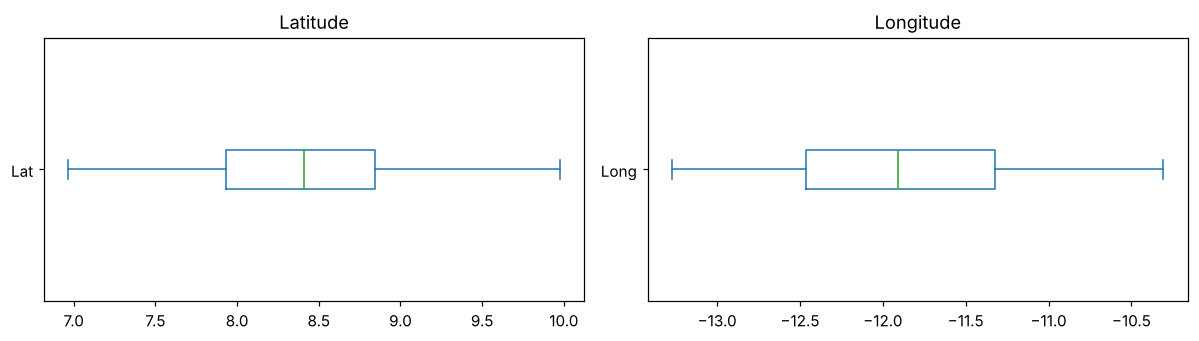

In [7]:
display(df[["Lat", "Long"]].describe())
# Sierra Leone's approximate extent: latitude 6.9–10.0 N, longitude 13.3–10.3 W
in_box = df["Lat"].between(6.9, 10.0) & df["Long"].between(-13.31, -10.26)
print("Facilities outside Sierra Leone's bounding box:", (~in_box).sum())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
df["Lat"].plot.box(ax=ax[0], vert=False, title="Latitude")
df["Long"].plot.box(ax=ax[1], vert=False, title="Longitude")
plt.tight_layout(); plt.show()

**Interpretation.** All coordinates are in Sierra Leone's latitude/longitude range, and the box plots show no extreme outliers. The coordinates have 4 decimal places (about 11 m precision). A finer check, whether each point falls inside a district polygon, is done during cleaning.

### 4.6 Visual overview

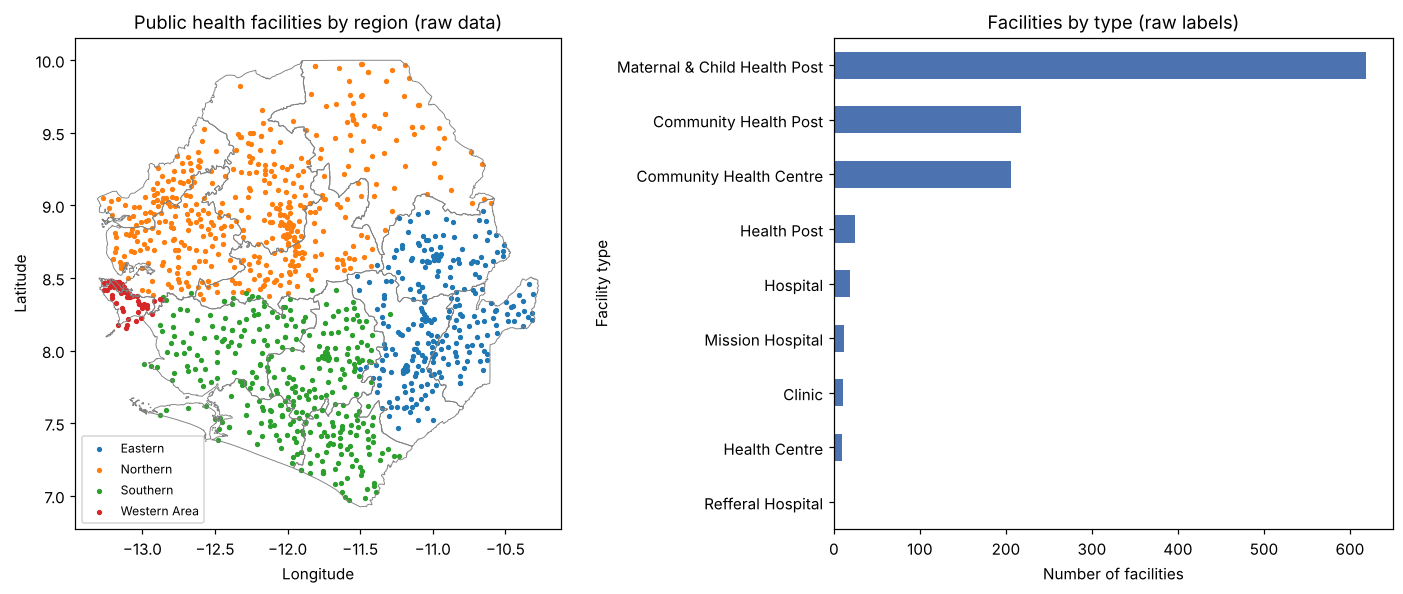

In [8]:
with open(DISTRICTS_GEOJSON) as f:
    gj = json.load(f)

def plot_boundaries(ax):
    for feat in gj["features"]:
        geom = shape(feat["geometry"])
        polys = geom.geoms if geom.geom_type == "MultiPolygon" else [geom]
        for p in polys:
            x, y = p.exterior.xy
            ax.plot(x, y, color="grey", linewidth=0.6)

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
plot_boundaries(ax[0])
for region, g in df.groupby("Admin1"):
    ax[0].scatter(g["Long"], g["Lat"], s=6, label=region)
ax[0].set_title("Public health facilities by region (raw data)")
ax[0].set_xlabel("Longitude"); ax[0].set_ylabel("Latitude"); ax[0].legend(fontsize=8)
ax[0].set_aspect("equal")

df["Facility type"].value_counts().sort_values().plot.barh(ax=ax[1], color="#4C72B0")
ax[1].set_title("Facilities by type (raw labels)"); ax[1].set_xlabel("Number of facilities")
plt.tight_layout(); plt.show()

**Interpretation.** Facilities are spread across the whole country, and the region labels match the map. Maternal & Child Health Posts (MCHPs) make up 55% of all facilities, so most of the public network is small primary-care units. Only 32 facilities are hospitals of any kind.

### 4.7 Summary of data-quality issues found

| # | Issue | Columns | Planned action |
|---|---|---|---|
| 1 | Column names contain spaces and capitals | all | Rename to snake_case |
| 2 | Constant column | Country | Drop |
| 3 | Spelling errors and abbreviations in labels and names | Facility type, Facility name | Correct |
| 4 | Same owner coded two ways ("MoH" / "Govt.") | Ownership | Standardise |
| 5 | Text stored as generic objects | Admin1, type, ownership, source | Convert to `category` |
| 6 | Possible duplicate facilities with the same name | Facility name | Check distance and remove true duplicates |
| 7 | No district column; data only at region level | — | Derive district from coordinates |
| 8 | Many types for the same level of care | Facility type | Group into standard levels |
| 9 | 14% of coordinates not from GPS | LL source | Flag lower-precision locations |
| 10 | No population data to compare access | — | Join 2015 census by district |

## 5. Data cleaning and preparation
Each step changes `df` and records what it did in `cleaning_log`, so every step is documented and can be repeated.

In [9]:
cleaning_log = []
def log(step, detail, rows_before, rows_after):
    cleaning_log.append({"step": step, "detail": detail,
                         "rows_before": rows_before, "rows_after": rows_after})

### 5.1 Standardise column names

In [10]:
n = len(df)
df = df.rename(columns={
    "Country": "country", "Admin1": "region", "Facility name": "facility_name",
    "Facility type": "facility_type", "Ownership": "ownership",
    "Lat": "latitude", "Long": "longitude", "LL source": "coord_source"})
log("Rename columns", "Converted to snake_case; Admin1 -> region", n, len(df))
df.columns.tolist()

['country',
 'region',
 'facility_name',
 'facility_type',
 'ownership',
 'latitude',
 'longitude',
 'coord_source']

### 5.2 Remove the constant column
`country` is 'Sierra Leone' in every row, so it adds nothing to the analysis.

In [11]:
assert df["country"].nunique() == 1
df = df.drop(columns="country")
log("Drop column", "Removed constant column 'country'", len(df), len(df))

### 5.3 Trim text and make capitalisation consistent
The raw file has no stray spaces, but this step runs anyway so the pipeline stays safe if the source is updated. Repeated internal spaces are reduced to one.

In [12]:
text_cols = ["region", "facility_name", "facility_type", "ownership", "coord_source"]
for c in text_cols:
    df[c] = df[c].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
log("Trim text", "Stripped and normalised whitespace in text columns", len(df), len(df))

### 5.4 Correct spelling errors and abbreviations
These corrections were found by reading every hospital and clinic name and every facility-type label. Only clear errors were changed. Names that might be official spellings were left alone.

In [13]:
type_fixes = {"Refferal Hospital": "Referral Hospital"}
name_fixes = {
    r"\bRefferal\b": "Referral",
    r"\bCannaught\b": "Connaught",
    r"\bGovt\b\.?": "Government",
    r"\bUbc\b": "UBC",
    r"Kamakwiewesleyanmiss": "Kamakwie Wesleyan Mission",
    r"\bMagburaku\b": "Magburaka",
}
before = df[["facility_name", "facility_type"]].copy()
df["facility_type"] = df["facility_type"].replace(type_fixes)
for pattern, repl in name_fixes.items():
    df["facility_name"] = df["facility_name"].str.replace(pattern, repl, regex=True)

changed = (before != df[["facility_name", "facility_type"]]).any(axis=1)
log("Fix spelling", f"Corrected {changed.sum()} records (type and name labels)", len(df), len(df))
pd.concat([before[changed].add_suffix("_before"), df.loc[changed, ["facility_name", "facility_type"]]], axis=1)

,facility_name_before,facility_type_before,facility_name,facility_type
355,Kabala Govt Hospital,Hospital,Kabala Government Hospital,Hospital
380,Kamakwiewesleyanmiss Hospital,Mission Hospital,Kamakwie Wesleyan Mission Hospital,Mission Hospital
506,Magburaku Government Hospital,Hospital,Magburaka Government Hospital,Hospital
899,Mattru Ubc Hospital,Mission Hospital,Mattru UBC Hospital,Mission Hospital
981,Refferal Hospital,Refferal Hospital,Referral Hospital,Referral Hospital
1069,Cannaught Hospital,Hospital,Connaught Hospital,Hospital


### 5.5 Standardise ownership
"MoH" and "Govt." both mean government (Ministry of Health and Sanitation), so they are combined. The short codes are replaced with clear labels.

In [14]:
ownership_map = {"MoH": "Government", "Govt.": "Government",
                 "FBO": "Faith-based organisation", "NGO": "Non-governmental organisation"}
unmapped = set(df["ownership"]) - set(ownership_map)
assert not unmapped, f"Unmapped ownership codes: {unmapped}"
df["ownership"] = df["ownership"].map(ownership_map)
log("Standardise ownership", "Merged 'MoH' and 'Govt.' into 'Government'; expanded codes", len(df), len(df))
df["ownership"].value_counts()

ownership
Government                       1095
Faith-based organisation           15
Non-governmental organisation      10
Name: count, dtype: int64

### 5.6 Group facility types into standard levels of care
Sierra Leone's Basic Package of Essential Health Services organises public care in levels. MCHPs and CHPs are the lowest-level Peripheral Health Units (PHUs), CHCs sit above them, and hospitals are at the top. The 9 raw labels are mapped to 5 levels so that districts can be compared fairly. The original label is kept in `facility_type`.

In [15]:
level_map = {
    "Maternal & Child Health Post": "MCHP (health post)",
    "Health Post": "MCHP (health post)",
    "Community Health Post": "CHP (community health post)",
    "Community Health Centre": "CHC (health centre)",
    "Health Centre": "CHC (health centre)",
    "Clinic": "Clinic",
    "Hospital": "Hospital",
    "Mission Hospital": "Hospital",
    "Referral Hospital": "Hospital",
}
assert set(df["facility_type"]) <= set(level_map), set(df["facility_type"]) - set(level_map)
df["facility_level"] = df["facility_type"].map(level_map)
df["is_hospital"] = df["facility_level"].eq("Hospital")
log("Derive facility_level", "Mapped 9 raw types to 5 standard levels; added is_hospital flag", len(df), len(df))
pd.crosstab(df["facility_type"], df["facility_level"])

facility_level,CHC (health centre),CHP (community health post),Clinic,Hospital,MCHP (health post)
facility_type,,,,,
Clinic,0,0,11,0,0
Community Health Centre,206,0,0,0,0
Community Health Post,0,217,0,0,0
Health Centre,10,0,0,0,0
Health Post,0,0,0,0,25
Hospital,0,0,0,19,0
Maternal & Child Health Post,0,0,0,0,619
Mission Hospital,0,0,0,12,0
Referral Hospital,0,0,0,1,0


### 5.7 Remove duplicate facilities
Section 4.4 found 39 rows sharing a name within a region. A pair is treated as a true duplicate only if it has the **same name and type and lies within 1 km**, which means it is the same building recorded twice. Pairs further apart are different facilities in villages with the same name and are kept. When a duplicate is removed, the record with GPS coordinates is kept.

In [16]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

pairs = []
for (_, _, _), g in df.groupby(["region", "facility_name", "facility_type"]):
    if len(g) < 2:
        continue
    idx = g.index.tolist()
    for i in range(len(idx)):
        for j in range(i+1, len(idx)):
            a, b = df.loc[idx[i]], df.loc[idx[j]]
            pairs.append({"facility_name": a.facility_name, "row_a": idx[i], "row_b": idx[j],
                          "distance_km": round(haversine_km(a.latitude, a.longitude, b.latitude, b.longitude), 2)})
pairs = pd.DataFrame(pairs).sort_values("distance_km")
display(pairs)

true_dups = pairs[pairs["distance_km"] < 1.0]
to_drop = []
for _, p in true_dups.iterrows():
    a, b = df.loc[p.row_a], df.loc[p.row_b]
    # keep the GPS record; if both are GPS keep the first
    to_drop.append(p.row_a if (a.coord_source != "GPS" and b.coord_source == "GPS") else p.row_b)

n = len(df)
df = df.drop(index=to_drop)
log("Remove duplicates", f"Dropped {len(to_drop)} record(s): same name/type within 1 km; "
    f"{len(pairs) - len(true_dups)} same-name pairs kept as distinct facilities", n, len(df))
print("Dropped rows:", to_drop, "| rows now:", len(df))

,facility_name,row_a,row_b,distance_km
1,Kpayama Maternal and Child Health Post,134,135,0.34
8,Masuba Maternal and Child Health Post,591,592,2.97
15,Manjama Community Health Centre,887,888,7.87
6,Masuba Maternal and Child Health Post,590,591,9.45
7,Masuba Maternal and Child Health Post,590,592,10.60
20,York Community Health Centre,1118,1119,12.35
0,Baoma Maternal and Child Health Post,16,17,21.82
3,Kalangba Maternal and Child Health Post,372,373,29.07
16,Saahun Maternal and Child Health Post,985,986,32.81
18,Taninahun Community Health Post,1018,1019,44.27


Dropped rows: [135] | rows now: 1119


**Result.** Only one pair, Kpayama MCHP (about 0.3 km apart), is the same facility recorded twice, so one copy is removed. The other same-name pairs are 3 km to more than 100 km apart and are different facilities. The three Masuba MCHPs are 3–9 km apart and are kept, but are worth checking with the District Health Management Team.

### 5.8 Check coordinate quality
A flag records whether each location came from GPS. Non-GPS points are kept, because removing them would make some areas look as if they had fewer facilities than they do, but analysts can filter them out if precise distances matter.

Coordinates are stored with mixed precision. Most have 4 decimal places, but a few have 6 (for example 8.094901). Rounding everything to 4 decimal places (about 11 m) makes them consistent. It also exposes a hidden problem: two facilities that seemed to have different coordinates actually share the same point.

In [17]:
df["coord_source"] = df["coord_source"].replace({"Other": "Other / unspecified"})
df["gps_verified"] = df["coord_source"].eq("GPS")
df["latitude"] = df["latitude"].round(4)
df["longitude"] = df["longitude"].round(4)

df["shared_location"] = df.duplicated(["latitude", "longitude"], keep=False)
log("Flag coordinates", f"Added gps_verified flag; rounded to 4 dp; {int(df['shared_location'].sum())} records flagged as sharing a location",
    len(df), len(df))
display(df["coord_source"].value_counts())
df.loc[df["shared_location"], ["facility_name", "facility_type", "ownership", "latitude", "longitude"]]

coord_source
GPS                    956
Other / unspecified    160
Google Earth             3
Name: count, dtype: int64

,facility_name,facility_type,ownership,latitude,longitude
965,Njala Clinic,Clinic,Government,8.0949,-12.0195
967,Njala Hospital,Hospital,Government,8.0949,-12.0195
1085,Iran S/L Medical Centre,Health Centre,Non-governmental organisation,8.4618,-13.1764
1086,Iran Sierra Leone Hospital,Hospital,Non-governmental organisation,8.4618,-13.1764


**Decision.** Two pairs of records have identical coordinates once rounded: *Njala Hospital / Njala Clinic*, and *Iran Sierra Leone Hospital / Iran S/L Medical Centre*. Each pair has different names and types, so they may be separate services on one site, or one facility listed twice. There isn't enough evidence to delete either, so all four are kept and flagged with `shared_location = True` for checking with the Ministry.

### 5.9 Derive district from coordinates (point-in-polygon)
Each facility's point is tested against the 14 district polygons. A first pass shows two problems:
1. Some points fall **outside every polygon**. These are mostly on the coast and islands, where the simplified boundary file cuts off land, so the district would be missing.
2. Some points fall inside a district that belongs to a **different region** from the one recorded in the data.

In [18]:
district_region = {
    "Kailahun": "Eastern", "Kenema": "Eastern", "Kono": "Eastern",
    "Bombali": "Northern", "Kambia": "Northern", "Koinadugu": "Northern",
    "Port Loko": "Northern", "Tonkolili": "Northern",
    "Bo": "Southern", "Bonthe": "Southern", "Moyamba": "Southern", "Pujehun": "Southern",
    "Western Area Rural": "Western Area", "Western Area Urban": "Western Area",
}
districts = {f["properties"]["shapeName"]: shape(f["geometry"]) for f in gj["features"]}
assert set(districts) == set(district_region)

def naive_district(lat, lon):
    pt = Point(lon, lat)
    return next((n for n, poly in districts.items() if poly.contains(pt)), np.nan)

naive = pd.Series([naive_district(la, lo) for la, lo in zip(df["latitude"], df["longitude"])], index=df.index)
outside = naive.isna()
conflict = naive.notna() & (naive.map(district_region) != df["region"])
print("Points outside every district polygon (would be missing):", outside.sum())
print("Points inside a district of a different region:", conflict.sum())

Points outside every district polygon (would be missing): 20
Points inside a district of a different region: 25


In [19]:
# How far is each problem point from the nearest district in its *recorded* region?
def nearest_in_region(lat, lon, region):
    pt = Point(lon, lat)
    cands = {n: p for n, p in districts.items() if district_region[n] == region}
    name = min(cands, key=lambda n: cands[n].distance(pt))
    return name, round(cands[name].distance(pt) * 111, 2)   # degrees -> approx. km

probe = df.loc[outside | conflict, ["facility_name", "region", "latitude", "longitude", "coord_source"]].copy()
probe["naive_district"] = naive[probe.index]
probe[["nearest_in_recorded_region", "distance_km"]] = [nearest_in_region(r.latitude, r.longitude, r.region) for r in probe.itertuples()]
probe["distance_km"] = probe["distance_km"].astype(float)
display(probe.sort_values("distance_km", ascending=False))
print(probe["distance_km"].describe().round(2))

,facility_name,region,latitude,longitude,coord_source,naive_district,nearest_in_recorded_region,distance_km
944,Moyamba Community Health Post,Southern,8.2510,-11.2975,Other / unspecified,Kenema,Bo,11.31
1097,Madaka Community Health Post,Western Area,8.3494,-12.8629,GPS,Port Loko,Western Area Rural,6.23
879,Makondu Maternal and Child Health Post,Southern,8.3949,-12.2866,GPS,Tonkolili,Moyamba,5.43
1049,Yele Community Health Centre,Southern,8.4140,-11.8330,GPS,Tonkolili,Bo,4.81
1089,Kent Community Health Centre,Western Area,8.1563,-13.1105,GPS,NaN,Western Area Rural,4.69
1110,Songo Community Health Centre,Western Area,8.3529,-12.8785,GPS,Port Loko,Western Area Rural,4.47
58,Fothaneh Junction Maternal and Child Health Post,Eastern,8.5906,-11.3832,GPS,Tonkolili,Kono,4.30
1118,York Community Health Centre,Western Area,8.2003,-13.0463,GPS,NaN,Western Area Rural,4.15
792,Gandorhun Community Health Post,Southern,7.6148,-11.4489,GPS,Kenema,Pujehun,4.10
50,Fanima Community Health Post,Eastern,7.7018,-11.5273,GPS,Bo,Kenema,3.97


count    45.00
mean      2.18
std       2.15
min       0.05
25%       0.60
50%       1.47
75%       2.86
max      11.31
Name: distance_km, dtype: float64


**Interpretation.** Almost all problem points lie **within about 6 km** of a district boundary in their recorded region. This is the pattern you would expect from boundary imprecision in a simplified boundary file, not from wrong labels. For example, two Freetown hospitals (African Muslim Agency and UMC Urban Centre) would otherwise be placed in Port Loko across the estuary. The region label comes from the Ministry's own list, so it is treated as reliable.

**Cleaning rule**
1. If the point lies inside a district of its recorded region, use that district.
2. Otherwise, assign the **nearest district within the recorded region** and record the distance.
3. If that distance is more than **7 km**, flag the location as suspect (`location_suspect = True`), because the coordinates are probably wrong.
4. **Manual override from local knowledge:** *Magburaka Government Hospital* is the district hospital of **Tonkolili**, but its point falls just across the simplified Bombali boundary. It is assigned to Tonkolili and the override is recorded.

In [20]:
manual_district = {"Magburaka Government Hospital": "Tonkolili"}

def assign_district(row):
    if row.facility_name in manual_district:
        return manual_district[row.facility_name], "manual override", 0.0
    nd = naive[row.Index]
    if pd.notna(nd) and district_region[nd] == row.region:
        return nd, "inside polygon", 0.0
    name, km = nearest_in_region(row.latitude, row.longitude, row.region)
    return name, "nearest district in recorded region", km

res = [assign_district(r) for r in df.itertuples()]
df["district"] = [r[0] for r in res]
df["district_assignment"] = [r[1] for r in res]
df["boundary_distance_km"] = [r[2] for r in res]
df["location_suspect"] = df["boundary_distance_km"] > 7

assert df["district"].notna().all()
assert (df["district"].map(district_region) == df["region"]).all()   # region and district now agree
print(df["district_assignment"].value_counts().to_string())
print("\nLocation-suspect records:")
display(df.loc[df["location_suspect"], ["facility_name", "region", "district", "boundary_distance_km", "coord_source"]])
log("Derive district", f"Point-in-polygon; {int(outside.sum())} missing and {int(conflict.sum())} cross-region points resolved "
    f"to nearest district in recorded region; 1 manual override; {int(df['location_suspect'].sum())} flagged suspect", len(df), len(df))

district_assignment
inside polygon                         1073
nearest district in recorded region      45
manual override                           1

Location-suspect records:


,facility_name,region,district,boundary_distance_km,coord_source
944,Moyamba Community Health Post,Southern,Bo,11.31,Other / unspecified


### 5.10 Consistency check
The checks above confirm that every facility now has exactly one district and that the district always belongs to the facility's recorded region. Nothing is missing, and the region and district columns agree.

In [21]:
pd.crosstab(df["district"], df["region"])

region,Eastern,Northern,Southern,Western Area
district,,,,
Bo,0,0,105,0
Bombali,0,110,0,0
Bonthe,0,0,51,0
Kailahun,72,0,0,0
Kambia,0,56,0,0
Kenema,115,0,0,0
Koinadugu,0,75,0,0
Kono,84,0,0,0
Moyamba,0,0,101,0


### 5.11 Set correct data types

In [22]:
for c in ["region", "district", "facility_type", "facility_level", "ownership", "coord_source", "district_assignment"]:
    df[c] = df[c].astype("category")
df["facility_name"] = df["facility_name"].astype("string")
df = df.reset_index(drop=True)
df.insert(0, "facility_id", [f"SLE-HF-{i+1:04d}" for i in range(len(df))])
log("Set dtypes", "Converted categorical columns to 'category'; added facility_id", len(df), len(df))
df.dtypes

facility_id                  str
region                  category
facility_name             string
facility_type           category
ownership               category
latitude                 float64
longitude                float64
coord_source            category
facility_level          category
is_hospital                 bool
gps_verified                bool
shared_location             bool
district                category
district_assignment     category
boundary_distance_km     float64
location_suspect            bool
dtype: object

### 5.12 Transform: aggregate to district level and join population
To compare access between districts, facility counts are related to population. District populations come from the **Statistics Sierra Leone 2015 Population and Housing Census**, and areas from official district figures. The 14 pre-2017 districts are used because they match both the census and the boundary file.

In [23]:
census = pd.DataFrame({
    "district": ["Kailahun", "Kenema", "Kono", "Bombali", "Kambia", "Koinadugu", "Port Loko",
                 "Tonkolili", "Bo", "Bonthe", "Moyamba", "Pujehun", "Western Area Rural", "Western Area Urban"],
    "population_2015": [526379, 609891, 506100, 606544, 345474, 409372, 615376,
                        531435, 575478, 200781, 318588, 346461, 444270, 1055964],
    "area_km2": [3940, 6345, 5391, 3876, 3031, 4951, 5719, 6288, 5463, 3547, 7012, 4179, 1228, 82],
})
assert census["population_2015"].sum() == 7092113   # national census total

counts = (df.groupby("district", observed=True)
            .agg(total_facilities=("facility_id", "count"),
                 hospitals=("is_hospital", "sum"),
                 chcs=("facility_level", lambda s: (s == "CHC (health centre)").sum()),
                 health_posts=("facility_level", lambda s: s.isin(["MCHP (health post)", "CHP (community health post)"]).sum()),
                 gps_share=("gps_verified", "mean"))
            .reset_index())

district_df = census.merge(counts, on="district", how="left", validate="one_to_one")
assert district_df["total_facilities"].notna().all() and district_df["total_facilities"].sum() == len(df)

district_df["region"] = district_df["district"].map(district_region)
district_df["facilities_per_10k"] = (district_df["total_facilities"] / district_df["population_2015"] * 10000).round(2)
district_df["people_per_facility"] = (district_df["population_2015"] / district_df["total_facilities"]).round(0).astype(int)
district_df["hospitals_per_100k"] = (district_df["hospitals"] / district_df["population_2015"] * 100000).round(2)
district_df["facilities_per_100km2"] = (district_df["total_facilities"] / district_df["area_km2"] * 100).round(2)
district_df["gps_share"] = district_df["gps_share"].round(3)
log("Aggregate + join", "Built 14-row district table joined to 2015 census; added per-capita and density metrics",
    len(df), len(district_df))
district_df.sort_values("facilities_per_10k")

,district,population_2015,area_km2,total_facilities,hospitals,chcs,health_posts,gps_share,region,facilities_per_10k,people_per_facility,hospitals_per_100k,facilities_per_100km2
13,Western Area Urban,1055964,82,19,7,9,3,0.842,Western Area,0.18,55577,0.66,23.17
12,Western Area Rural,444270,1228,43,4,15,21,0.814,Western Area,0.97,10332,0.90,3.50
0,Kailahun,526379,3940,72,2,14,56,1.000,Eastern,1.37,7311,0.38,1.83
4,Kambia,345474,3031,56,1,9,46,0.821,Northern,1.62,6169,0.29,1.85
2,Kono,506100,5391,84,1,11,72,0.833,Eastern,1.66,6025,0.20,1.56
7,Tonkolili,531435,6288,91,1,11,79,0.824,Northern,1.71,5840,0.19,1.45
3,Bombali,606544,3876,110,3,19,87,0.882,Northern,1.81,5514,0.49,2.84
8,Bo,575478,5463,105,2,32,69,0.933,Southern,1.82,5481,0.35,1.92
5,Koinadugu,409372,4951,75,1,11,61,0.693,Northern,1.83,5458,0.24,1.51
1,Kenema,609891,6345,115,3,23,89,1.000,Eastern,1.89,5303,0.49,1.81


### 5.13 Outlier check on district indicators
The interquartile range (IQR) rule (below Q1 − 1.5×IQR or above Q3 + 1.5×IQR) is applied to the per-capita indicator to find districts that differ sharply from the rest.

IQR bounds: 1.21 – 2.34 facilities per 10,000


,district,population_2015,total_facilities,facilities_per_10k
9,Bonthe,200781,51,2.54
10,Moyamba,318588,101,3.17
12,Western Area Rural,444270,43,0.97
13,Western Area Urban,1055964,19,0.18


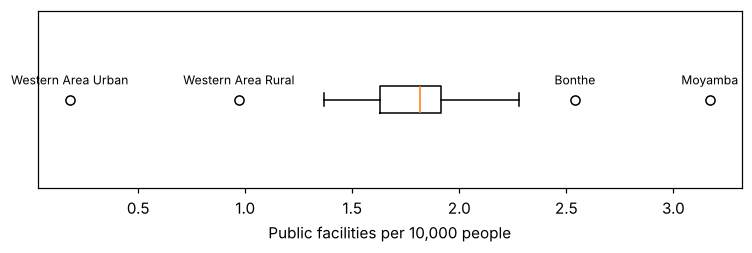

In [24]:
s = district_df["facilities_per_10k"]
q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
district_df["per_capita_outlier"] = ~s.between(lo, hi)
print(f"IQR bounds: {lo:.2f} – {hi:.2f} facilities per 10,000")
display(district_df.loc[district_df["per_capita_outlier"], ["district", "population_2015", "total_facilities", "facilities_per_10k"]])

fig, ax = plt.subplots(figsize=(7, 2.4))
ax.boxplot(s, orientation="horizontal"); ax.set_xlabel("Public facilities per 10,000 people"); ax.set_yticks([])
for _, r in district_df[district_df["per_capita_outlier"]].iterrows():
    ax.annotate(r["district"], (r["facilities_per_10k"], 1), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=8)
plt.tight_layout(); plt.show()

**Decision.** The two Western Area districts are low outliers, and Western Area Urban (Freetown) is extreme, with roughly ten times fewer public facilities per person than most provincial districts. Bonthe and Moyamba are high outliers because they have many small health posts serving small, spread-out (often riverine or island) populations. **None of these are data errors to remove.** The Freetown figure also reflects a coverage limitation: the WHO database **excludes private clinics and hospitals**, which are concentrated in the capital. All districts are kept and flagged with `per_capita_outlier`, and the limitation is stated in the report.

### 5.14 Final validation and export

In [25]:
assert df["facility_id"].is_unique
assert df.isna().sum().sum() == 0, "Unexpected missing values"
assert df["latitude"].between(6.9, 10.0).all() and df["longitude"].between(-13.31, -10.26).all()
assert set(df["district"].unique()) == set(census["district"])
print("All checks passed.")
print("Clean facility table:", df.shape, "| District table:", district_df.shape)

df.to_csv("sle_health_facilities_clean.csv", index=False)
district_df.to_csv("sle_district_health_access.csv", index=False)
print("Saved sle_health_facilities_clean.csv and sle_district_health_access.csv")
display(df.head())

All checks passed.
Clean facility table: (1119, 16) | District table: (14, 14)
Saved sle_health_facilities_clean.csv and sle_district_health_access.csv


,facility_id,region,facility_name,facility_type,ownership,latitude,longitude,coord_source,facility_level,is_hospital,gps_verified,shared_location,district,district_assignment,boundary_distance_km,location_suspect
0,SLE-HF-0001,Eastern,Ahmadiyya Mission Hospital,Mission Hospital,Faith-based organisation,7.8883,-11.1881,GPS,Hospital,True,True,False,Kenema,inside polygon,0.0,False
1,SLE-HF-0002,Eastern,Baama Community Health Centre,Community Health Centre,Government,8.3588,-11.3329,GPS,CHC (health centre),False,True,False,Kenema,inside polygon,0.0,False
2,SLE-HF-0003,Eastern,Baiama Community Health Post,Community Health Post,Government,8.5167,-10.9677,GPS,CHP (community health post),False,True,False,Kono,inside polygon,0.0,False
3,SLE-HF-0004,Eastern,Baiima Community Health Post,Community Health Post,Government,8.0293,-10.7648,GPS,CHP (community health post),False,True,False,Kailahun,inside polygon,0.0,False
4,SLE-HF-0005,Eastern,Baiwala Community Health Post,Community Health Post,Government,7.9956,-10.6477,GPS,CHP (community health post),False,True,False,Kailahun,inside polygon,0.0,False


## 6. First look at the research questions
This is descriptive only. Modelling and statistical testing belong to later assignments.

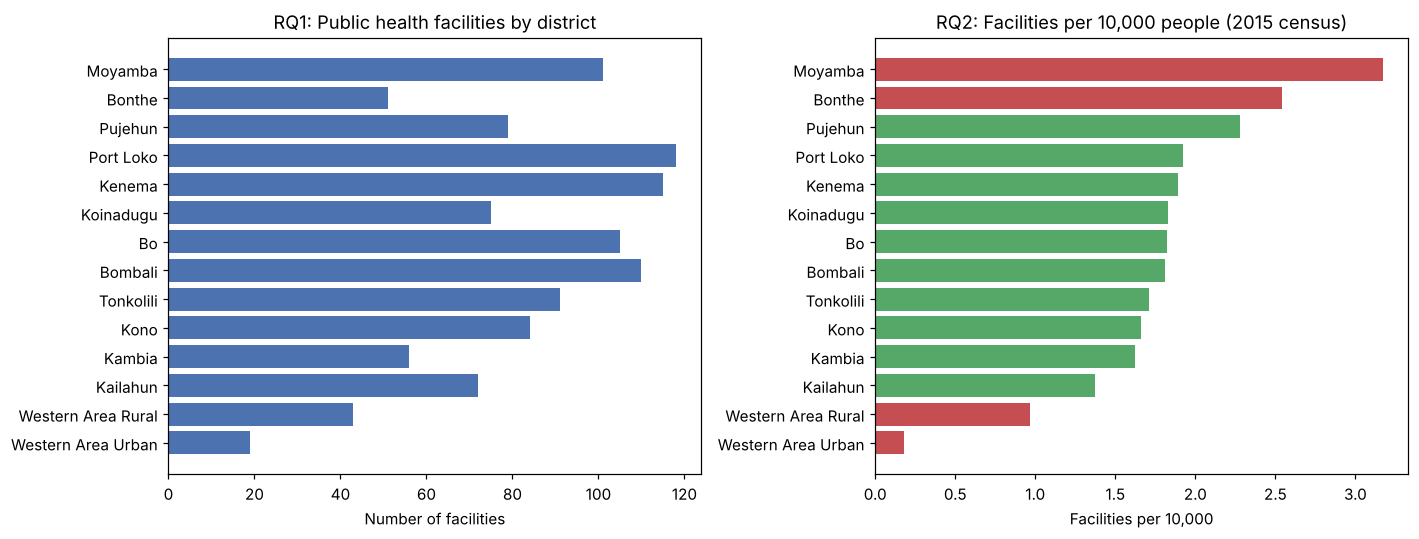

In [26]:
d = district_df.sort_values("facilities_per_10k")
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].barh(d["district"], d["total_facilities"], color="#4C72B0")
ax[0].set_title("RQ1: Public health facilities by district"); ax[0].set_xlabel("Number of facilities")
colors = ["#C44E52" if o else "#55A868" for o in d["per_capita_outlier"]]
ax[1].barh(d["district"], d["facilities_per_10k"], color=colors)
ax[1].set_title("RQ2: Facilities per 10,000 people (2015 census)"); ax[1].set_xlabel("Facilities per 10,000")
plt.tight_layout(); plt.show()

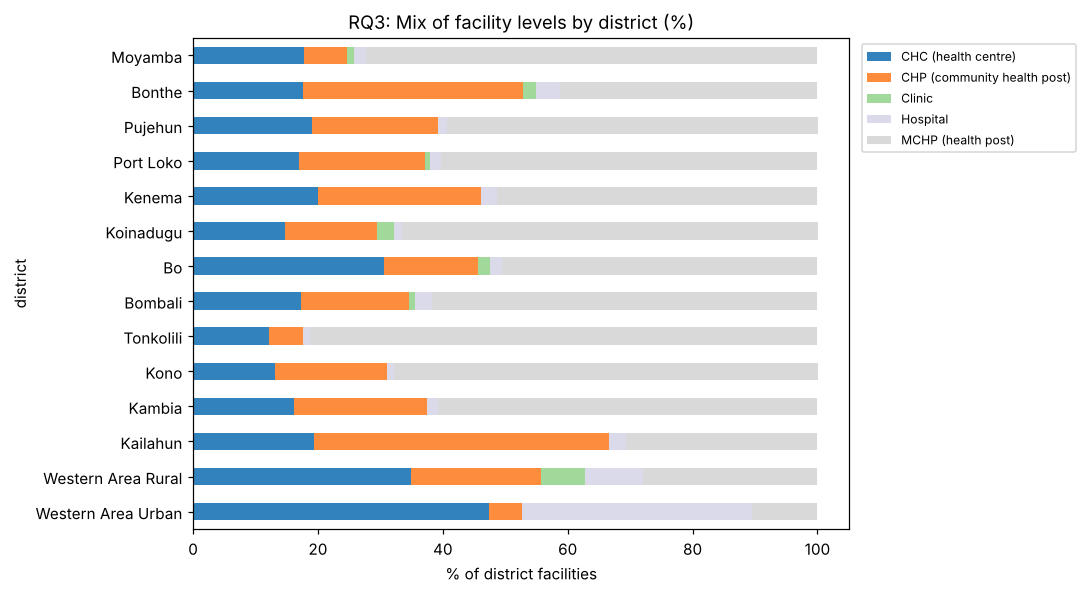

facility_level,CHC (health centre),CHP (community health post),Clinic,Hospital,MCHP (health post)
district,,,,,
Western Area Urban,47.4,5.3,0.0,36.8,10.5
Western Area Rural,34.9,20.9,7.0,9.3,27.9
Kailahun,19.4,47.2,0.0,2.8,30.6
Kambia,16.1,21.4,0.0,1.8,60.7
Kono,13.1,17.9,0.0,1.2,67.9
Tonkolili,12.1,5.5,0.0,1.1,81.3
Bombali,17.3,17.3,0.9,2.7,61.8
Bo,30.5,15.2,1.9,1.9,50.5
Koinadugu,14.7,14.7,2.7,1.3,66.7


In [27]:
mix = (pd.crosstab(df["district"], df["facility_level"], normalize="index") * 100).round(1)
mix = mix.loc[d["district"]]
ax = mix.plot.barh(stacked=True, figsize=(10, 5.5), colormap="tab20c")
ax.set_title("RQ3: Mix of facility levels by district (%)"); ax.set_xlabel("% of district facilities")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8); plt.tight_layout(); plt.show()
mix

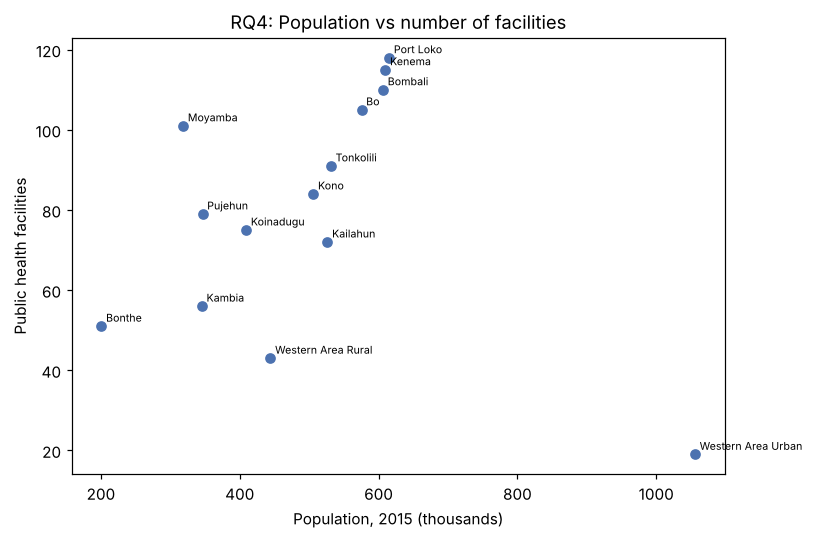

Pearson r, all 14 districts: -0.12
Pearson r, excluding Western Area Urban: 0.68


In [28]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(district_df["population_2015"]/1000, district_df["total_facilities"], color="#4C72B0")
for _, r in district_df.iterrows():
    ax.annotate(r["district"], (r["population_2015"]/1000, r["total_facilities"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Population, 2015 (thousands)"); ax.set_ylabel("Public health facilities")
ax.set_title("RQ4: Population vs number of facilities"); plt.tight_layout(); plt.show()

r_all = district_df["population_2015"].corr(district_df["total_facilities"])
no_wau = district_df[district_df["district"] != "Western Area Urban"]
r_ex = no_wau["population_2015"].corr(no_wau["total_facilities"])
print(f"Pearson r, all 14 districts: {r_all:.2f}")
print(f"Pearson r, excluding Western Area Urban: {r_ex:.2f}")

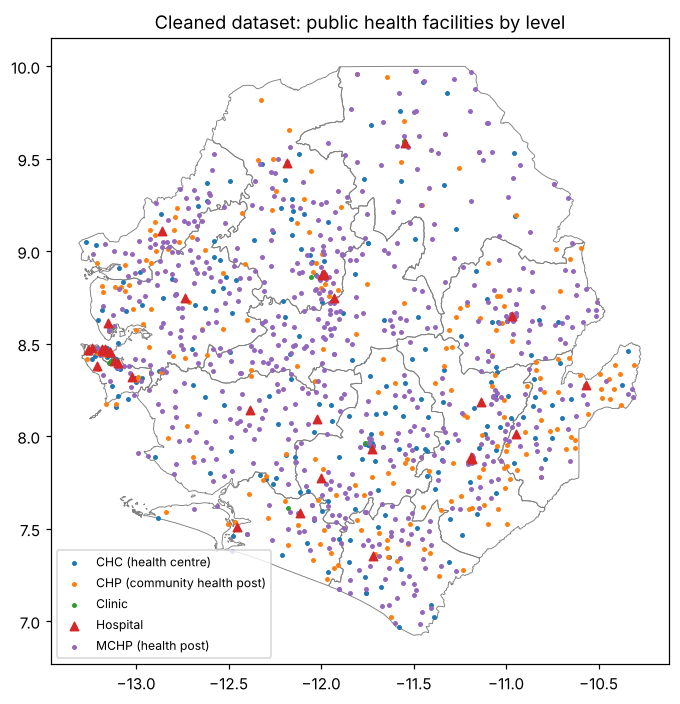

In [29]:
fig, ax = plt.subplots(figsize=(7, 6.5))
plot_boundaries(ax)
for lvl, g in df.groupby("facility_level", observed=True):
    ax.scatter(g["longitude"], g["latitude"], s=30 if lvl == "Hospital" else 5, label=lvl,
               marker="^" if lvl == "Hospital" else "o", zorder=3 if lvl == "Hospital" else 2)
ax.set_title("Cleaned dataset: public health facilities by level"); ax.set_aspect("equal")
ax.legend(fontsize=8, loc="lower left"); plt.tight_layout(); plt.show()

## 7. Data ethics notes
- **Privacy:** The dataset holds only facility-level information (names, types, locations of public buildings). It has **no personal or patient data**, so individual privacy risk is minimal. The census figures are published aggregates.
- **Ownership and licensing:** The data belong to the WHO and the Sierra Leone Ministry of Health and Sanitation and are openly published for non-commercial research. Both are cited, and the data are not presented as my own.
- **Bias and representativeness:** Private facilities are excluded and the list is a 2019 snapshot. Any conclusion that Freetown is "under-served" would be misleading without that caveat. Census data from 2015 also do not reflect later population growth or the 2017 district reorganisation.
- **Responsible use:** The results describe distribution, not service quality, staffing or drug availability. They should support, not replace, local knowledge from District Health Management Teams.

## 8. Cleaning log and references

In [30]:
log_df = pd.DataFrame(cleaning_log)
log_df.index = log_df.index + 1
log_df

,step,detail,rows_before,rows_after
1,Rename columns,Converted to snake_case; Admin1 -> region,1120,1120
2,Drop column,Removed constant column 'country',1120,1120
3,Trim text,Stripped and normalised whitespace in text col...,1120,1120
4,Fix spelling,Corrected 6 records (type and name labels),1120,1120
5,Standardise ownership,Merged 'MoH' and 'Govt.' into 'Government'; ex...,1120,1120
6,Derive facility_level,Mapped 9 raw types to 5 standard levels; added...,1120,1120
7,Remove duplicates,Dropped 1 record(s): same name/type within 1 k...,1120,1119
8,Flag coordinates,Added gps_verified flag; rounded to 4 dp; 4 re...,1119,1119
9,Derive district,Point-in-polygon; 20 missing and 25 cross-regi...,1119,1119
10,Set dtypes,Converted categorical columns to 'category'; a...,1119,1119


**References**
- Maina, J., Ouma, P. O., Macharia, P. M., Alegana, V. A., Mitto, B., Fall, I. S., Noor, A. M., Snow, R. W. and Okiro, E. A. (2019). A spatial database of health facilities managed by the public health sector in sub-Saharan Africa. *Scientific Data*, 6, 134. https://doi.org/10.1038/s41597-019-0142-2
- World Health Organization (2019). *A spatial database of health facilities managed by the public health sector in sub-Saharan Africa* (WHO/CDS/GMP/2019.01). https://www.who.int/publications/m/item/who-cds-gmp-2019-01
- South, A. et al. (2020). *afrihealthsites: R package for African health facility locations* (afrimapr). https://github.com/afrimapr/afrihealthsites
- Runfola, D. et al. (2020). geoBoundaries: A global database of political administrative boundaries. *PLoS ONE*, 15(4), e0231866. https://www.geoboundaries.org
- Statistics Sierra Leone (2016). *2015 Population and Housing Census: Summary of Final Results*. Freetown: Stats SL.
- McKinney, W. (2010). Data structures for statistical computing in Python. *Proc. 9th Python in Science Conference*. (pandas)
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering*, 9(3), 90–95.
- Gillies, S. et al. (2007–). *Shapely*. https://github.com/shapely/shapely